# EXPLORATORY DATA ANALYSIS OF REGRESSION DATA
The purpose of this notebook is to explore our regression dataset. We will;
- Explore the data structure for each company.
- Verify if there are missing values.
- Check for duplicate rows.
- Analyze the feature summary statistics for each company.
- Explore the distribution of each feature for each company and check for outliers.
- Explore the relationship between features for each company.

In [23]:
# Import need libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels
from pathlib import Path
import os

In [24]:
# Specify file path for regression data
parent_dir = 'd:/projects/Capstone Project/Fundamental-Analysis-and-Earnings-Modeling/'
data_dir = parent_dir + 'data/processed/'
walmart_file = data_dir + 'WMT_regression.csv'
target_file = data_dir + 'TGT_regression.csv'
dollartree_file = data_dir + 'DLTR_regression.csv'
dollargeneral_file = data_dir + 'DG_regression.csv'
costco_file = data_dir + 'COST_regression.csv'


## Load Dataset, Check data type and Structure

In [25]:
# Load all regression data
walmart_df = pd.read_csv(walmart_file)
target_df = pd.read_csv(target_file)
dollartree_df = pd.read_csv(dollartree_file)
dollargeneral_df = pd.read_csv(dollargeneral_file)
costco_df = pd.read_csv(costco_file)

# Add ticker column to each dataframe for identification
walmart_df['Ticker'] = 'WMT'
target_df['Ticker'] = 'TGT'
dollartree_df['Ticker'] = 'DLTR'
dollargeneral_df['Ticker'] = 'DG'
costco_df['Ticker'] = 'COST'

# Stack all regression data into a single dataframe for easier analysis
merged_df = pd.concat([walmart_df, target_df, dollartree_df, dollargeneral_df, costco_df], axis=0)

# Divide each numerical column in the dataframe by a billion to make the values more readable
# merged_df[merged_df.select_dtypes(include=[np.number]).columns] = merged_df.select_dtypes(include=[np.number]) / 1e9

# Display information about the dataframe including column data types and non-null counts
merged_df.info()


<class 'pandas.DataFrame'>
Index: 380 entries, 0 to 72
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Total Revenue      380 non-null    int64  
 1   Cost of Revenue    380 non-null    int64  
 2   Operating Expense  380 non-null    int64  
 3   Interest Expense   380 non-null    float64
 4   Net Income         380 non-null    int64  
 5   Ticker             380 non-null    str    
dtypes: float64(1), int64(4), str(1)
memory usage: 22.0 KB


## Check for Missing Values.

In [26]:
# Check for Missing values in the merged dataframe
print(merged_df.isnull().sum())



Total Revenue        0
Cost of Revenue      0
Operating Expense    0
Interest Expense     0
Net Income           0
Ticker               0
dtype: int64


## Check for Duplicate Rows.

In [27]:
# Check for duplicate rows in the merged dataframe
print(merged_df.duplicated().sum())

0


In [28]:
# Display summary statistics to get an overview of the merged data distribution
print(merged_df.describe())

       Total Revenue  Cost of Revenue  Operating Expense  Interest Expense  \
count   3.800000e+02     3.800000e+02       3.800000e+02      3.800000e+02   
mean    4.055161e+10     3.107387e+10       7.515402e+09      1.759533e+08   
std     4.962839e+10     3.766346e+10       1.004272e+10      2.240532e+08   
min     9.712000e+08     6.446000e+08       2.630000e+08      0.000000e+00   
25%     5.549975e+09     3.859800e+09       1.298519e+09      2.734500e+07   
50%     1.752000e+10     1.278000e+10       3.087000e+09      5.686350e+07   
75%     5.464425e+10     4.793250e+10       6.051500e+09      1.922500e+08   
max     1.906560e+11     1.436150e+11       3.975000e+10      8.430000e+08   

         Net Income  
count  3.800000e+02  
mean   1.188359e+09  
std    1.594118e+09  
min   -3.695900e+09  
25%    2.470688e+08  
50%    5.465000e+08  
75%    1.502000e+09  
max    7.891000e+09  


## Review Summary Statistics of Features for each Company.

In [29]:
# Check company specific summary statistics(only count,mean,std,min,max) and generate a table
summary_stats = merged_df.groupby('Ticker').describe().loc[:, pd.IndexSlice[:, ['count', 'mean', 'std', 'min', 'max']]]
print(summary_stats)

       Total Revenue                                                          \
               count          mean           std           min           max   
Ticker                                                                         
COST            73.0  3.965518e+10  1.901405e+10  1.580600e+10  9.572300e+10   
DG              79.0  6.122839e+09  2.777176e+09  2.275267e+09  1.129038e+10   
DLTR            79.0  3.978582e+09  2.263682e+09  9.712000e+08  8.639900e+09   
TGT             70.0  2.097829e+10  4.750572e+09  1.483300e+10  3.191900e+10   
WMT             79.0  1.297252e+11  2.544200e+10  8.641000e+10  1.906560e+11   

       Cost of Revenue                                            \
                 count          mean           std           min   
Ticker                                                             
COST              73.0  3.460063e+10  1.662714e+10  1.377600e+10   
DG                79.0  4.235230e+09  1.917584e+09  1.642207e+09   
DLTR              7

## Compare Feature Distribution among Companies

Box plots for Total Revenue


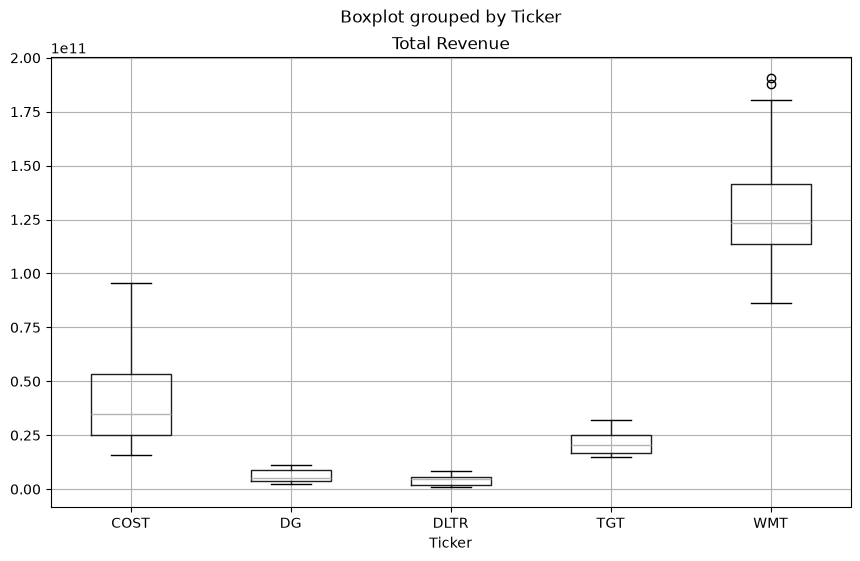

Box plots for Cost of Revenue


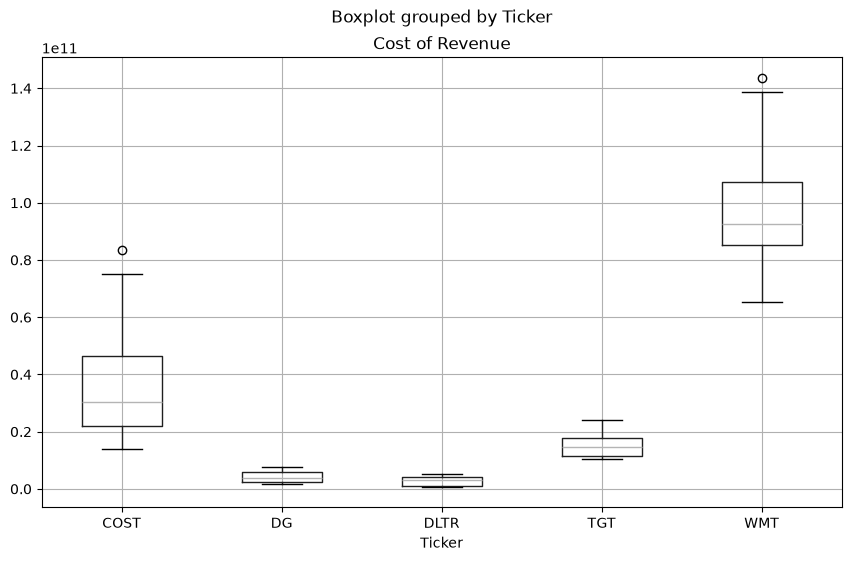

Box plots for Operating Expense


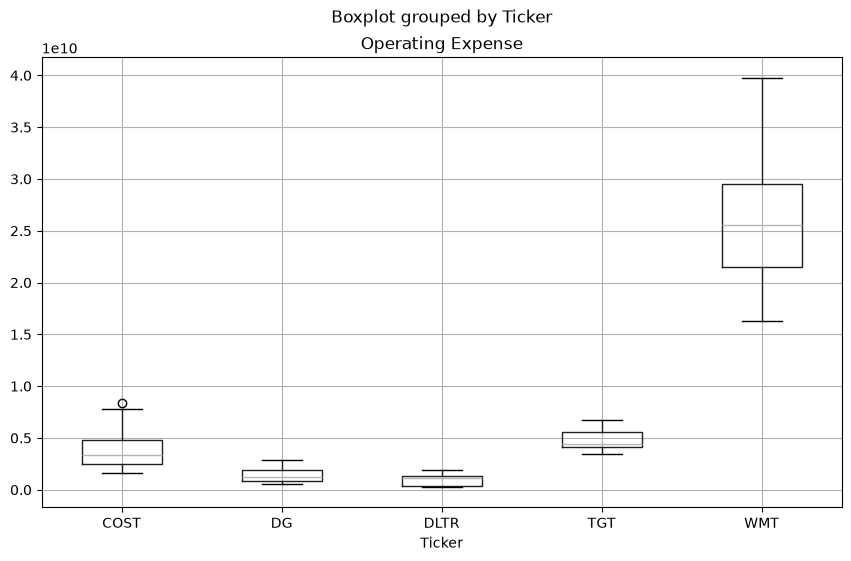

Box plots for Interest Expense


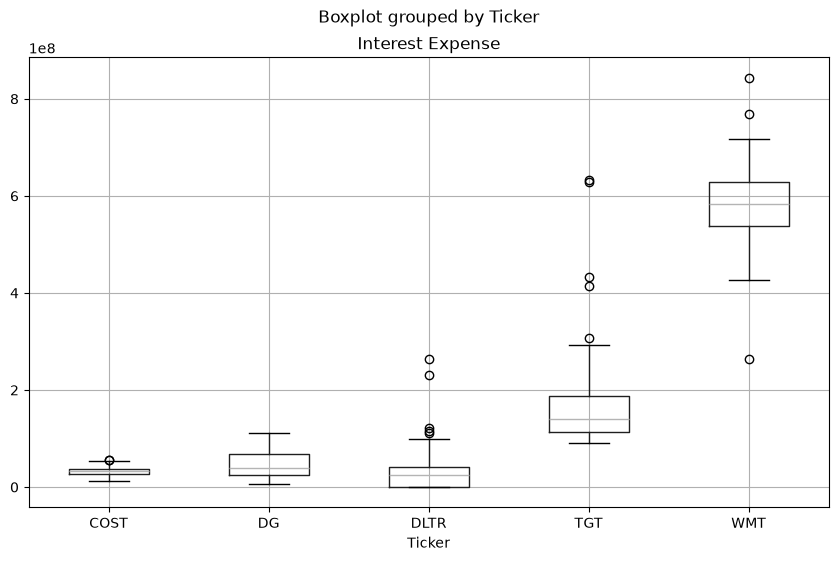

Box plots for Net Income


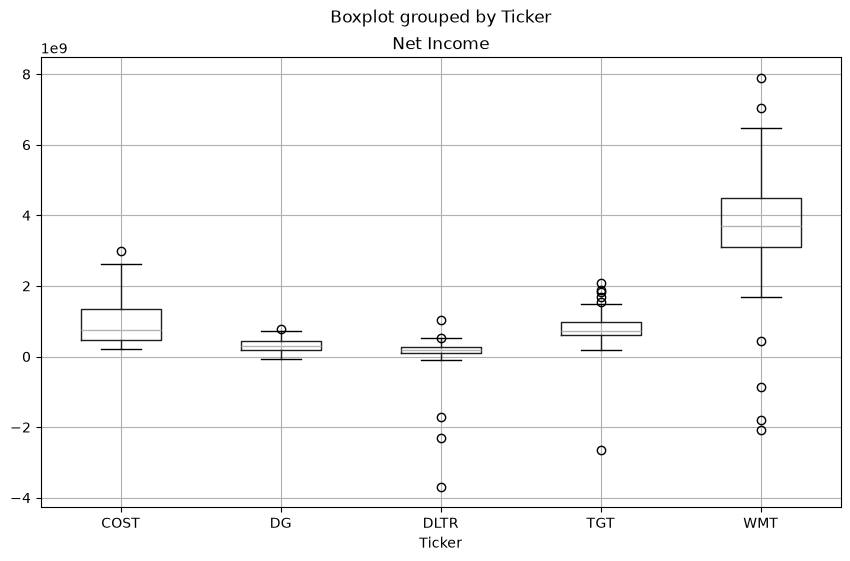

In [30]:
# Compare box plots among different companies for each numerical feature
numerical_cols = merged_df.select_dtypes(include=[np.number]).columns
for col in numerical_cols:
    print(f"Box plots for {col}")
    merged_df.boxplot(column=col, by='Ticker', figsize=(10,6))
    plt.show()

## Visualize the Relationship between Features

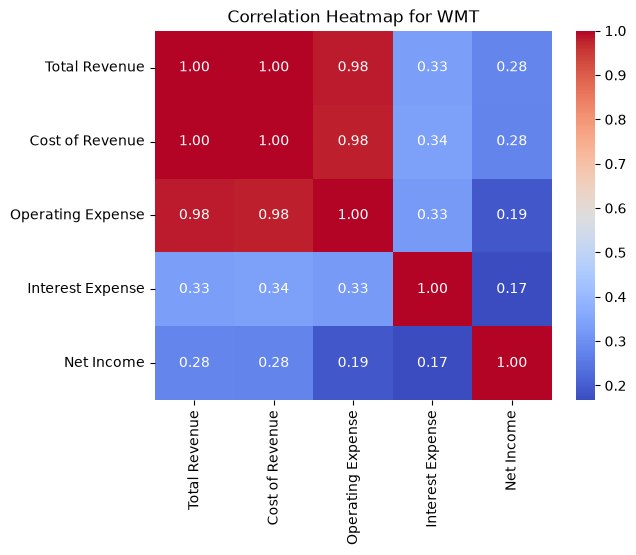

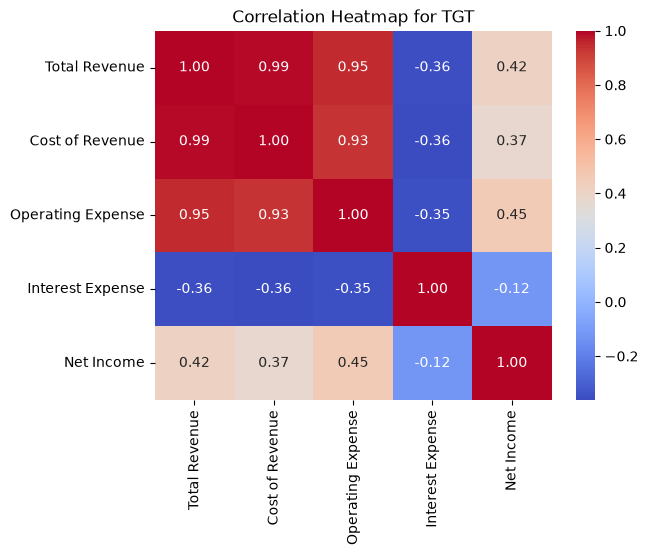

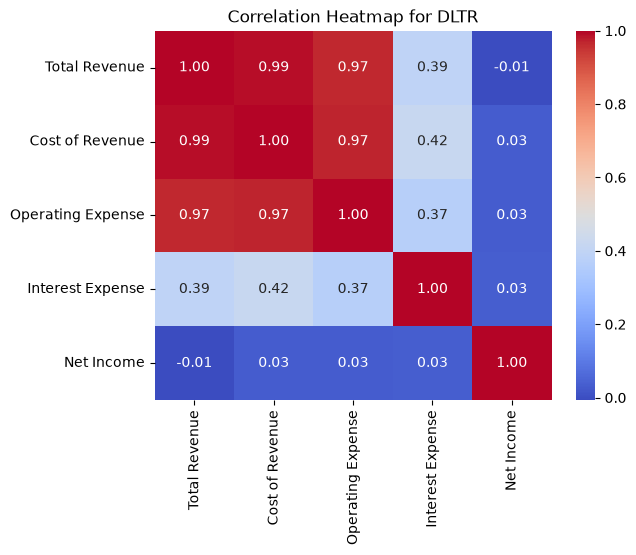

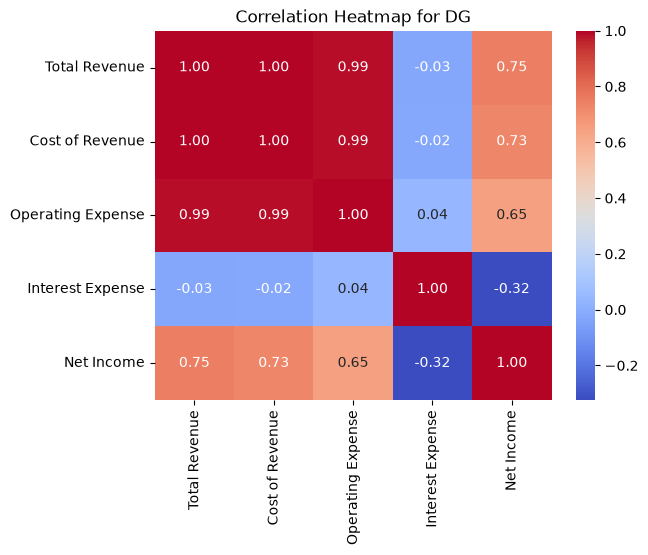

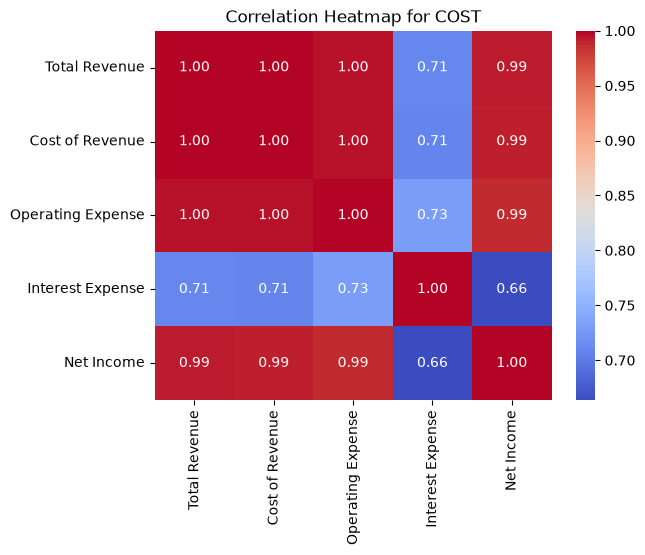

In [31]:
# Create a heatmap matrix to visualize correlations between features excluding the 'Ticker' column for each company in merged_df
for ticker in merged_df['Ticker'].unique():
    company_df = merged_df[merged_df['Ticker'] == ticker]
    sns.heatmap(company_df.drop(columns='Ticker').corr(), annot=True, cmap='coolwarm', fmt='.2f')
    plt.title(f'Correlation Heatmap for {ticker}')
    plt.show()


In [32]:
# Check for multicollinearity for each company's dataframe columns except for Net Income
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Check for multicollinearity for each company's dataframe
vif_results = {}
for ticker, group_df in merged_df.groupby('Ticker'):
    X = group_df.select_dtypes(include=[np.number]).drop(columns=['Net Income'])
    vif_data = pd.DataFrame()
    vif_data["feature"] = X.columns
    vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(len(X.columns))]
    vif_results[ticker] = vif_data
vif_results

{'COST':              feature           VIF
 0      Total Revenue  46874.130833
 1    Cost of Revenue  39292.062268
 2  Operating Expense    475.557494
 3   Interest Expense      2.464912,
 'DG':              feature         VIF
 0      Total Revenue  729.691186
 1    Cost of Revenue  838.444573
 2  Operating Expense   59.317881
 3   Interest Expense    1.247774,
 'DLTR':              feature        VIF
 0      Total Revenue  57.572862
 1    Cost of Revenue  73.883380
 2  Operating Expense  18.866881
 3   Interest Expense   1.298534,
 'TGT':              feature         VIF
 0      Total Revenue  136.135001
 1    Cost of Revenue  103.615354
 2  Operating Expense   11.569723
 3   Interest Expense    1.160662,
 'WMT':              feature          VIF
 0      Total Revenue  1222.368130
 1    Cost of Revenue  1006.747852
 2  Operating Expense    36.983034
 3   Interest Expense     1.156565}

In [33]:
# Check for multicollinearity for each company's dataframe columns except for Net Income
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Check for multicollinearity for each company's dataframe
vif_results = {}
for ticker, group_df in merged_df.groupby('Ticker'):
    X = group_df.select_dtypes(include=[np.number]).drop(columns=['Net Income','Cost of Revenue','Operating Expense'])
    vif_data = pd.DataFrame()
    vif_data["feature"] = X.columns
    vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(len(X.columns))]
    vif_results[ticker] = vif_data
vif_results

{'COST':             feature      VIF
 0     Total Revenue  2.01386
 1  Interest Expense  2.01386,
 'DG':             feature       VIF
 0     Total Revenue  1.000898
 1  Interest Expense  1.000898,
 'DLTR':             feature       VIF
 0     Total Revenue  1.183595
 1  Interest Expense  1.183595,
 'TGT':             feature      VIF
 0     Total Revenue  1.14636
 1  Interest Expense  1.14636,
 'WMT':             feature       VIF
 0     Total Revenue  1.125316
 1  Interest Expense  1.125316}

In [34]:
# Calculate Cost of Revenue as a percentage of Total Revenue
merged_df['Cost of Revenue %'] = merged_df['Cost of Revenue'] / merged_df['Total Revenue'] * 100
# Calculate Operating Expense as a percentage of Total Revenue
merged_df['Operating Expense %'] = merged_df['Operating Expense'] / merged_df['Total Revenue'] * 100
# Calculate Interest Expense as a percentage of Total Revenue
merged_df['Interest Expense %'] = merged_df['Interest Expense'] / merged_df['Total Revenue'] * 100
# Calculate Net Income as a percentage of Total Revenue
merged_df['Net Income %'] = merged_df['Net Income'] / merged_df['Total Revenue'] * 100

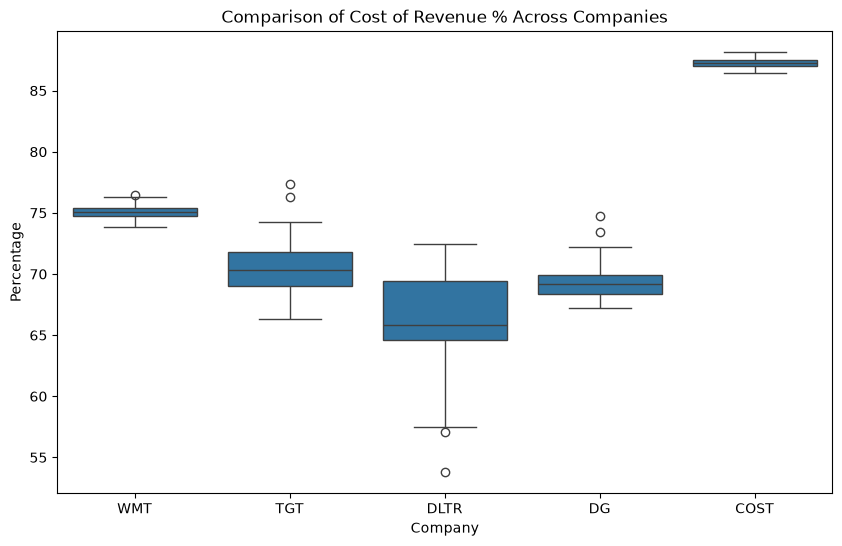

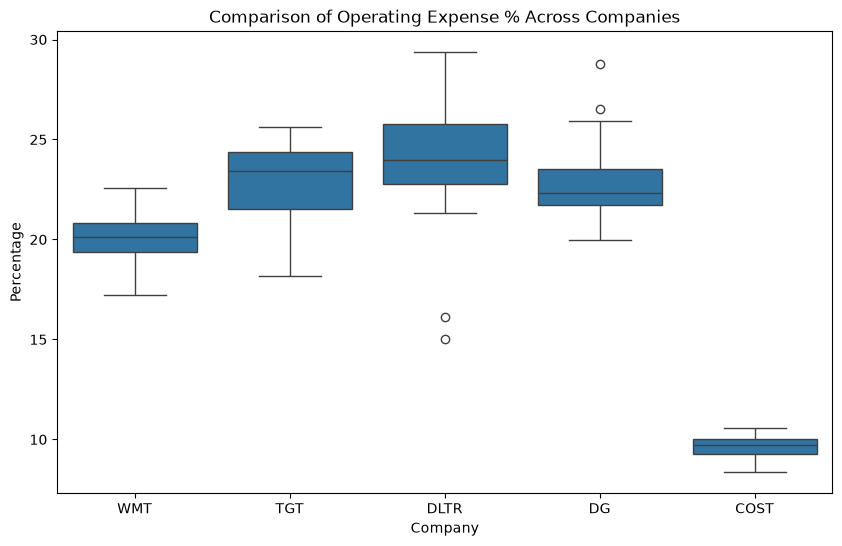

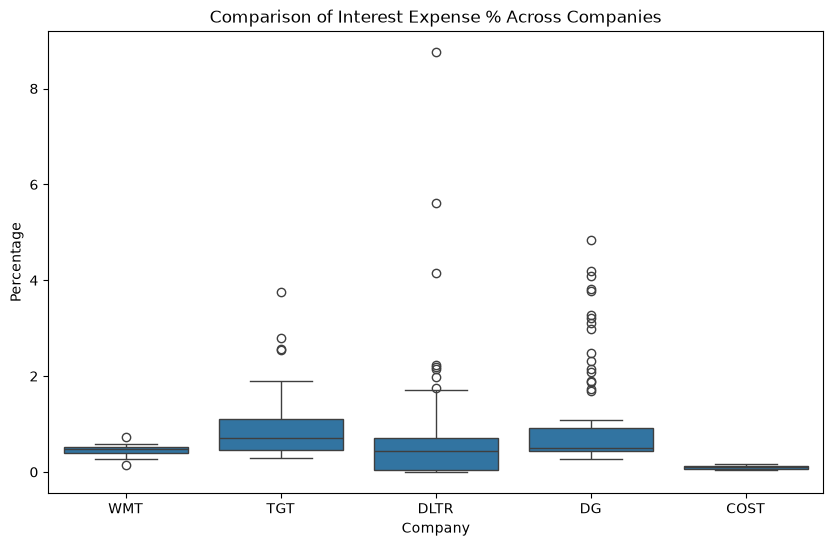

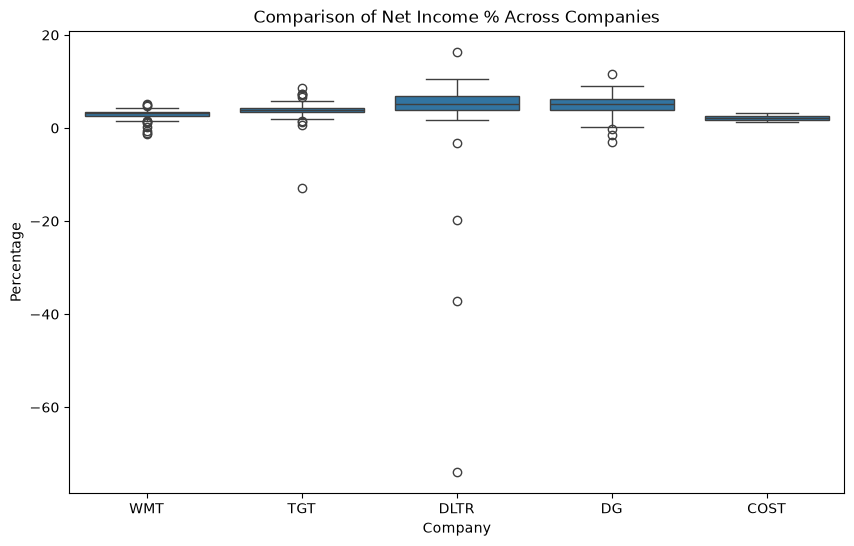

In [35]:
# Compare box plots among different companies for each percentage column
percentage_columns = ['Cost of Revenue %', 'Operating Expense %', 'Interest Expense %', 'Net Income %']
for col in percentage_columns:
    plt.figure(figsize=(10,6))
    sns.boxplot(x='Ticker', y=col, data=merged_df)
    plt.title(f'Comparison of {col} Across Companies')
    plt.ylabel('Percentage')
    plt.xlabel('Company')
    plt.show()

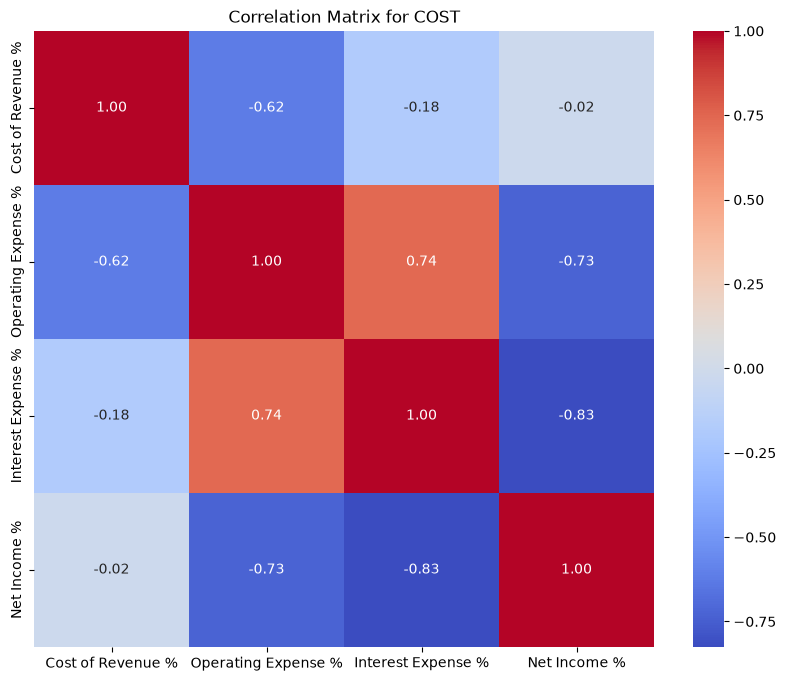

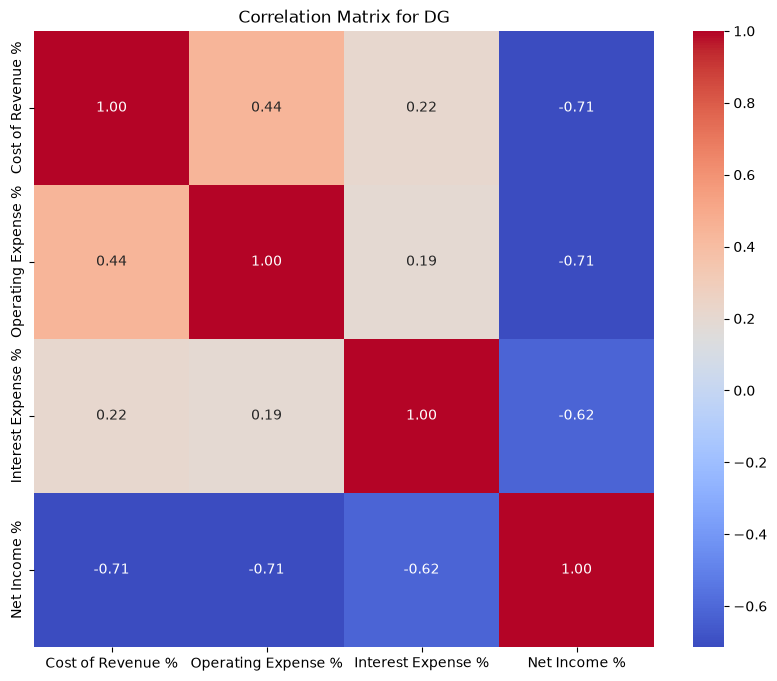

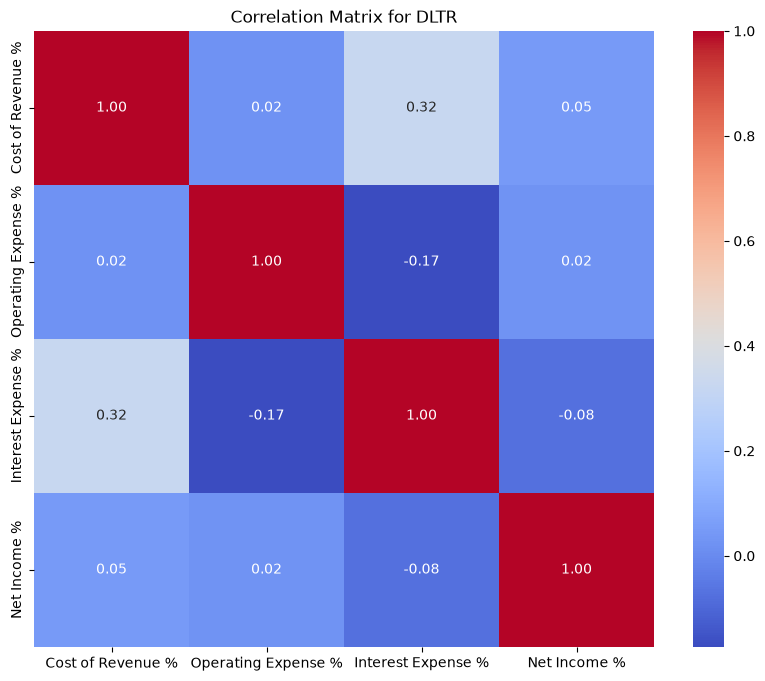

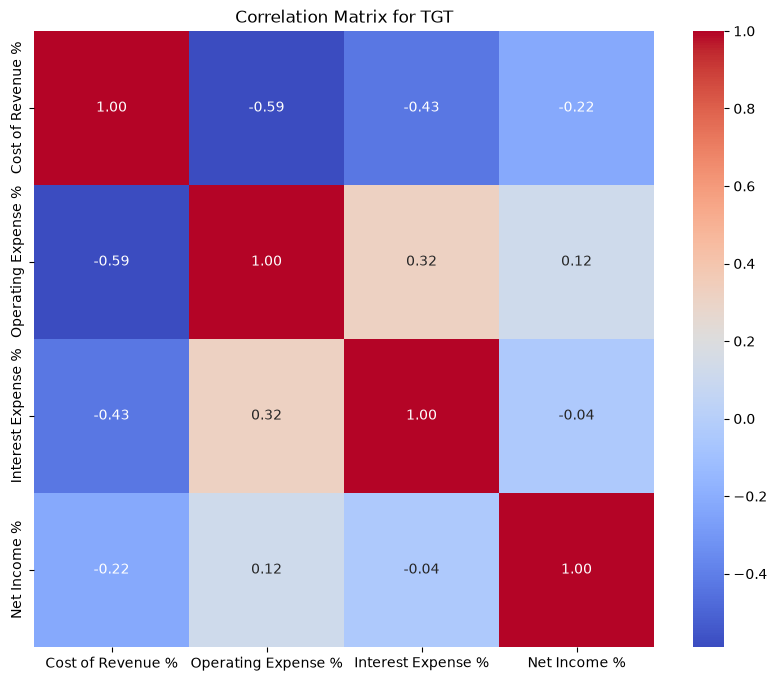

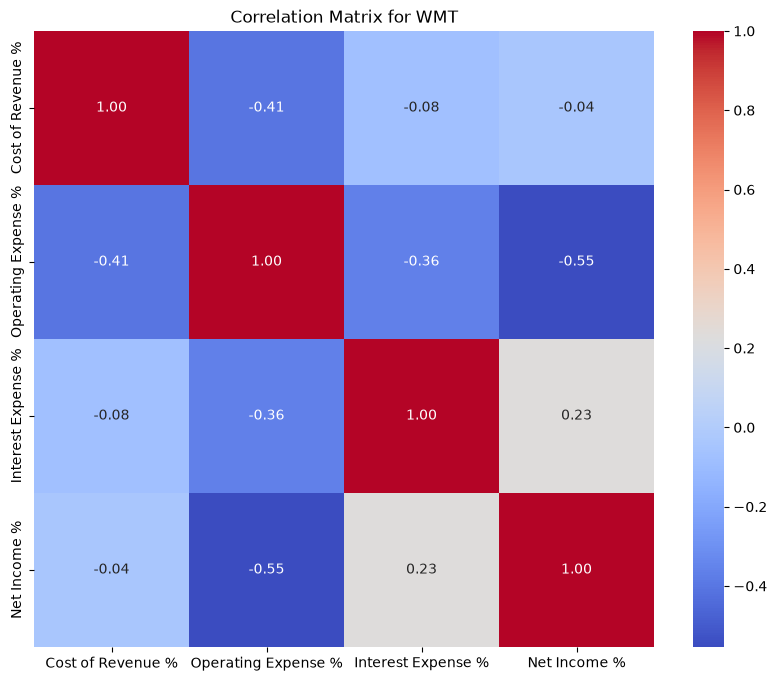

In [36]:
# Visualize a heatmap of the correlation matrix for each company's dataframe with percentage columns
import seaborn as sns

for ticker, group_df in merged_df.groupby('Ticker'):
    plt.figure(figsize=(10,8))
    corr_matrix = group_df[['Cost of Revenue %', 'Operating Expense %', 'Interest Expense %', 'Net Income %']].corr()
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
    plt.title(f'Correlation Matrix for {ticker}')
    plt.show()

In [37]:
# Variance Inflation Factor (VIF) for percentage columns excluding the target column for each company
for ticker, group_df in merged_df.groupby('Ticker'):
    X = group_df[[col for col in percentage_columns if col != 'Net Income %']]
    vif_data = pd.DataFrame()
    vif_data["feature"] = X.columns
    vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(len(X.columns))]
    print(f"VIF for {ticker}")
    print(vif_data)
    print()

VIF for COST
               feature       VIF
0    Cost of Revenue %  2.237471
1  Operating Expense %  4.745100
2   Interest Expense %  3.019302

VIF for DG
               feature       VIF
0    Cost of Revenue %  1.273035
1  Operating Expense %  1.261423
2   Interest Expense %  1.062570

VIF for DLTR
               feature       VIF
0    Cost of Revenue %  1.124775
1  Operating Expense %  1.038078
2   Interest Expense %  1.159321

VIF for TGT
               feature       VIF
0    Cost of Revenue %  1.699244
1  Operating Expense %  1.544445
2   Interest Expense %  1.237384

VIF for WMT
               feature       VIF
0    Cost of Revenue %  1.284933
1  Operating Expense %  1.473515
2   Interest Expense %  1.238546



In [38]:
# Detect,print and Drop Outliers
for ticker in merged_df["Ticker"].unique():
    filtered_df = merged_df[merged_df["Ticker"] == ticker]
    for col in filtered_df.select_dtypes(include="number").columns:
        Q1 = filtered_df[col].quantile(0.25)
        Q3 = filtered_df[col].quantile(0.75)
        IQR = Q3 - Q1
        outliers = filtered_df[(filtered_df[col] < (Q1 - 1.5 * IQR)) | (filtered_df[col] > (Q3 + 1.5 * IQR))]
        print(f"Outliers for {ticker} in {col}:")
        # print count of outliers
        print(f"Count of outliers: {len(outliers)}")

       

Outliers for WMT in Total Revenue:
Count of outliers: 2
Outliers for WMT in Cost of Revenue:
Count of outliers: 1
Outliers for WMT in Operating Expense:
Count of outliers: 0
Outliers for WMT in Interest Expense:
Count of outliers: 3
Outliers for WMT in Net Income:
Count of outliers: 6
Outliers for WMT in Cost of Revenue %:
Count of outliers: 1
Outliers for WMT in Operating Expense %:
Count of outliers: 0
Outliers for WMT in Interest Expense %:
Count of outliers: 2
Outliers for WMT in Net Income %:
Count of outliers: 11
Outliers for TGT in Total Revenue:
Count of outliers: 0
Outliers for TGT in Cost of Revenue:
Count of outliers: 0
Outliers for TGT in Operating Expense:
Count of outliers: 0
Outliers for TGT in Interest Expense:
Count of outliers: 5
Outliers for TGT in Net Income:
Count of outliers: 6
Outliers for TGT in Cost of Revenue %:
Count of outliers: 2
Outliers for TGT in Operating Expense %:
Count of outliers: 0
Outliers for TGT in Interest Expense %:
Count of outliers: 4
Outlie

In [39]:
# Create new dataframe with only percentage columns and ticker
ml_df = merged_df[[col for col in merged_df.columns if '%' in col or col == 'Ticker']]
print(ml_df)

   Ticker  Cost of Revenue %  Operating Expense %  Interest Expense %  \
0     WMT          76.268193            17.239952            0.432992   
1     WMT          75.700004            17.894776            0.561306   
2     WMT          75.700172            18.455589            0.513215   
3     WMT          75.064012            18.549771            0.459301   
4     WMT          74.903747            18.217601            0.491578   
..    ...                ...                  ...                 ...   
68   COST          88.163571             8.372751            0.066583   
69   COST          87.686695             8.790332            0.070941   
70   COST          87.315708             8.867335            0.061483   
71   COST          87.094340             9.027810            0.053392   
72   COST          87.263249             8.765918            0.047011   

    Net Income %  
0       3.975656  
1       3.812786  
2       3.475201  
3       4.075635  
4       5.204538  
..       

In [40]:
# view full net income percentage data for DLTR where value is between -74 and -19 and that of TGT is less than -10
impairment_1= ml_df.loc[(ml_df["Ticker"] == "DLTR") & (ml_df["Net Income %"].between(-74, -19)), "Net Income %"]
impairment_2 = ml_df.loc[(ml_df["Ticker"] == "TGT") & (ml_df["Net Income %"] < -10), "Net Income %"]
impairment = pd.concat([impairment_1, impairment_2])
print(impairment)

# Drop impairment rows
ml_df = ml_df.drop(impairment.index)

12   -37.178495
17   -19.789581
18   -73.920957
5    -12.922173
Name: Net Income %, dtype: float64


In [41]:
# Save the percentage columns dataframe to a CSV file
parent_dir = Path.cwd().parent
os.makedirs(parent_dir / "data/processed", exist_ok=True)
save_path = parent_dir / "data/processed/ml_data.csv"
ml_df.to_csv(save_path, index=False)